# [실습] LangChain으로 데이터 생성하기




이번 실습에서는 Continuous Pretrain과 Instruction Tuning을 위한 데이터 생성에 대해 알아보겠습니다.



In [ ]:
!pip install langchain langchain-community langchain-openai langchain-ollama

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 28.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.6/99.6 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 6.7 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [ ]:
%pip install langchain-google

In [ ]:
%pip install langchain-google-genai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.8/68.8 kB 2.7 MB/s eta 0:00:00


In [ ]:
from langchain_core.prompts import PromptTemplate
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.prompts import FewShotPromptTemplate

In [ ]:
#from langchain_core.schema.output_parser import StrOutputParser
from langchain_core.output_parsers import StrOutputParser

In [ ]:
import os
import json
from dotenv import load_dotenv

load_dotenv('.env',override=True)

True

# LLM 설정하기

무료 API: Gemini를 사용하는 경우 분당 10회 제한을 고려하여 Rate Limiter를 설정합니다.

In [ ]:
from langchain_core.rate_limiters import InMemoryRateLimiter
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_openai import ChatOpenAI


# rate limiter를 LLM에 적용
llm = ChatOpenAI(
    model="gpt-4.1",
    temperature=0,
)

In [ ]:
llm.invoke("안녕")

AIMessage(content='안녕하세요! 무엇을 도와드릴까요? 😊', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 12, 'prompt_tokens': 9, 'total_tokens': 21, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-2025-04-14', 'system_fingerprint': 'fp_b76fb08f92', 'id': 'chatcmpl-Dn0bJ9cosvAeuRUbOEmUk6zjc9Pet', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019e9268-08cf-74d1-86e4-9b466601d934-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 9, 'output_tokens': 12, 'total_tokens': 21, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

## 도메인 코퍼스 만들기

Continous Pretraining을 위한 Corpus를 생성합니다.   
코퍼스는 지식 학습에 매우 중요한 역할을 수행하며, 정확성이 매우 중요하기 때문에   
일반적으로는 API, 외부 자료 수집 등을 통해 구성하는 것이 효과적입니다.

In [ ]:
try:
    disease_list = open('./disease_list.txt','r').read().strip().split(',')
except:
    search_prompt = '''
사회 취약 계층을 위한 의료 정보 책자를 만들고자 합니다.
해당 책자에는 다양한 질환의 정의와 증상, 치료 방법, 이후의 관리 방법이 포함됩니다.
자료 수집을 위해, 대표적인 10개의 질환 목록을 선정하세요.
각 단어의 한국어 명칭을 , 로 구분하여 나열해 주세요. 예시: 단어1, 단어2, ... 단어10
단어 이외의 다른 내용은 출력하지 마세요.
한글 명칭만 작성하세요.
'''
    disease_list = llm.invoke(search_prompt).content.split(', ')
    with open('disease_list.txt','w') as f:
        f.write(','.join(disease_list))
    f.close()

In [ ]:
len(disease_list)

10

In [ ]:
disease_list

['고혈압', '당뇨병', '심근경색', '뇌졸중', '폐렴', '결핵', '치매', '우울증', '관절염', '암']

생성된 질환에 대해, 세부 사항을 작성하기 위한 카테고리를 구성합니다.

In [ ]:
from langchain_core.prompts import ChatPromptTemplate
from itertools import product
from typing import List, Dict
import json
from tqdm import tqdm  # 진행상황 표시용
from datetime import datetime
import time

# 카테고리 옵션 정의
category_options = {
   # 문서 주제 분류
   'document_type': [
      # 일반 소개 관련
      'Symptoms', # 증상
      'General Information', # 일반 정보
      'Frequently Asked Questions', # 자주 묻는 질문

       # 약물치료 관련
       'Drug types and mechanisms',        # 약물 종류와 작용기전
       'Administration and precautions',   # 투약 방법과 주의사항
       'Side effects management',          # 부작용 관리

       # 수술 관련
       'Surgical indications',             # 수술 적응증
       'Procedure overview',               # 수술 과정 개요
       'Post-operative care',              # 수술 후 관리

       # 생활습관 관련
       'Diet and exercise',                # 식이요법과 운동
       'Daily life management',            # 일상생활 관리
       'Prevention guidelines',            # 예방 지침

       # 진단과 치료계획 관련
       'Diagnostic process',               # 진단 과정
       'Treatment strategy',               # 치료 전략
       'Progress monitoring',              # 경과 관찰

   ],

   # 상세도 수준 다양화
   'level': ['Standard', 'Expert', 'For Elderly (easy to understand)']
}

Combination의 개수를 구합니다.

In [ ]:
combinations = list(product(disease_list, category_options['document_type'], category_options['level']))
len(combinations)

450

In [ ]:
arguments = [{'disease':x[0],'document_type':x[1],'level':x[2]} for x in combinations]
arguments[0]

{'disease': '고혈압', 'document_type': 'Symptoms', 'level': 'Standard'}

이제, 생성 프롬프트 체인을 만들고 배치로 실행합니다.

In [ ]:
from langchain_core.runnables import RunnablePassthrough, RunnableParallel

medical_prompt = ChatPromptTemplate([
   ('system', '''You are a medical professor creating training data for healthcare AI development.

Core Principle: Each document must be self-contained and complete within its specific scope.

Writing Guidelines:
- Maintain medical accuracy while emphasizing logical flow
- Include evidence-based, up-to-date medical knowledge
- When using medical terms, include explanations in parentheses
- Write output in Korean language with clear and precise explanations
- Focus on information relevant to vulnerable populations
- Write comprehensive content within your assigned scope
- Use natural medical language without artificial boundaries

Document Type Focus - Write ONLY about:

1. **Drug types and mechanisms**: Pharmacological classifications, receptor mechanisms, metabolic pathways, drug action principles
2. **Administration and precautions**: Dosing schedules, administration routes, drug interactions, contraindications, timing considerations
3. **Side effects management**: Adverse event identification, severity assessment, management protocols, when to discontinue
4. **Surgical indications**: Surgical criteria, risk-benefit analysis, timing decisions, patient selection factors
5. **Procedure overview**: Surgical techniques, anesthesia types, procedural steps, equipment and technology used
6. **Post-operative care**: Wound management, pain control, activity progression, complication monitoring
7. **Diet and exercise**: Nutritional requirements, food restrictions, exercise prescriptions, activity modifications
8. **Daily life management**: Work adaptations, home environment modifications, assistive devices, social considerations
9. **Prevention guidelines**: Risk factor modification, screening protocols, preventive medications, lifestyle interventions
10. **Diagnostic process**: Test selection, diagnostic criteria, differential diagnosis, result interpretation
11. **Treatment strategy**: Treatment algorithms, therapy selection criteria, combination approaches, escalation protocols
12. **Progress monitoring**: Follow-up intervals, monitoring parameters, outcome measurements, treatment response criteria
13. **Frequently Asked Questions**: Common misconceptions, practical concerns, cost considerations, healthcare access
14. **General Introduction**: Disease definition, epidemiology, pathophysiology, natural history, disease burden

Remember:
- Each document should be complete and informative within its designated scope
- Write for medically vulnerable populations with clear explanations
- All content must be written in Korean language
- Focus exclusively on your document type without mentioning other aspects'''),

   ('user', '''Please write comprehensive medical content about {disease}.
Document type: {document_type}
Detail level: {level}

Create a thorough, naturally flowing medical document that completely covers this specific aspect of {disease}.
Ensure the content is self-contained and professionally written.
Please write the entire response in Korean.''')
])

llm_chain = medical_prompt | llm | StrOutputParser()

generate_chain = RunnableParallel(metadata = RunnablePassthrough(), result = llm_chain)

# generated_corpus = generate_chain.batch(arguments[0:2])

In [ ]:
import json
from datetime import datetime
import time

# 배치 크기 설정 (API 제한 고려)
BATCH_SIZE = 10  # 한 번에 처리할 개수, 30 => 10
generated_corpus = []
failed_items = []

# 전체 조합을 배치로 나누기
batches = [combinations[i:i+BATCH_SIZE] for i in range(0, len(combinations), BATCH_SIZE)]

# 진행상황 표시하며 처리
for batch_idx, batch in enumerate(tqdm(batches, desc="Processing batches")):
    try:
        # 각 배치의 arguments 준비
        batch_args = [
            {
                'disease': disease,
                'document_type': doc_type,
                'level': level
            }
            for disease, doc_type, level in batch
        ]

        # 배치 처리
        results = generate_chain.batch(batch_args)

        # 결과에 인덱스 추가하여 저장
        for (disease, doc_type, level), result in zip(batch, results):
            generated_corpus.append({
                'index': len(generated_corpus),
                'disease': disease,
                'document_type': doc_type,
                'level': level,
                'content': result['result'],
                'metadata': result['metadata'],
                'timestamp': datetime.now().isoformat()
            })

        # 중간 저장 (3번 배치마다)
        if (batch_idx + 1) % 3 == 0:
            with open(f'corpus_checkpoint_{batch_idx+1}.json', 'w', encoding='utf-8') as f:
                json.dump(generated_corpus, f, ensure_ascii=False, indent=2)
            print(f"Checkpoint saved: {len(generated_corpus)} documents")

    except Exception as e:
        print(f"Error in batch {batch_idx}: {e}")
        failed_items.extend(batch)
        continue

    # API 제한 방지용 대기
    time.sleep(1)

# 최종 결과 저장
with open('medical_corpus_result.json', 'w', encoding='utf-8') as f:
    json.dump({
        'total_documents': len(generated_corpus),
        'generation_date': datetime.now().isoformat(),
        'failed_items': len(failed_items),
        'documents': generated_corpus
    }, f, ensure_ascii=False, indent=2)

print(f"완료: {len(generated_corpus)}개 생성, {len(failed_items)}개 실패")

Processing batches:   4%|▍         | 2/45 [00:49<17:40, 24.67s/it]

Checkpoint saved: 30 documents


Processing batches:  13%|█▎        | 6/45 [02:18<14:33, 22.39s/it]

Error in batch 5: Error code: 429 - {'error': {'message': 'Rate limit reached for gpt-4.1 in organization org-nvioKrTsAXE2GIrD7mrLf0JQ on tokens per min (TPM): Limit 30000, Used 30000, Requested 754. Please try again in 1.508s. Visit https://platform.openai.com/account/rate-limits to learn more.', 'type': 'tokens', 'param': None, 'code': 'rate_limit_exceeded'}}


Processing batches:  16%|█▌        | 7/45 [02:33<12:41, 20.03s/it]

Error in batch 6: Error code: 429 - {'error': {'message': 'Rate limit reached for gpt-4.1 in organization org-nvioKrTsAXE2GIrD7mrLf0JQ on tokens per min (TPM): Limit 30000, Used 30000, Requested 746. Please try again in 1.492s. Visit https://platform.openai.com/account/rate-limits to learn more.', 'type': 'tokens', 'param': None, 'code': 'rate_limit_exceeded'}}


... (64 outputs left out)

Processing batches:  98%|█████████▊| 44/45 [12:43<00:14, 14.54s/it]

Error in batch 43: Error code: 429 - {'error': {'message': 'Rate limit reached for gpt-4.1 in organization org-nvioKrTsAXE2GIrD7mrLf0JQ on tokens per min (TPM): Limit 30000, Used 30000, Requested 742. Please try again in 1.484s. Visit https://platform.openai.com/account/rate-limits to learn more.', 'type': 'tokens', 'param': None, 'code': 'rate_limit_exceeded'}}


Processing batches: 100%|██████████| 45/45 [13:01<00:00, 17.37s/it]

Error in batch 44: Error code: 429 - {'error': {'message': 'Rate limit reached for gpt-4.1 in organization org-nvioKrTsAXE2GIrD7mrLf0JQ on tokens per min (TPM): Limit 30000, Used 30000, Requested 742. Please try again in 1.484s. Visit https://platform.openai.com/account/rate-limits to learn more.', 'type': 'tokens', 'param': None, 'code': 'rate_limit_exceeded'}}
완료: 90개 생성, 360개 실패


생성된 데이터를 확인해 보겠습니다.

In [ ]:
import json

with open ("medical_corpus_result.json", "r", encoding='utf-8') as f:
    data = json.load(f)
len(data['documents'])

90

In [ ]:
#data['documents'][292]
data['documents'][49]

{'index': 49,
 'disease': '당뇨병',
 'document_type': 'General Information',
 'level': 'Expert',
 'content': '당뇨병: 정의, 역학, 병태생리, 자연경과, 질병 부담\n\n정의  \n당뇨병(糖尿病, Diabetes Mellitus)은 인슐린(췌장에서 분비되는 혈당 조절 호르몬)의 분비 또는 작용에 이상이 생겨 만성적으로 혈당(혈중 포도당) 수치가 상승하는 대사성 질환입니다. 대표적으로 제1형 당뇨병(인슐린 분비 결핍)과 제2형 당뇨병(인슐린 저항성 및 상대적 결핍)이 있으며, 임신성 당뇨병, 기타 특수 유형(유전성, 약물 유발 등)도 포함됩니다.\n\n역학  \n전 세계적으로 당뇨병 유병률은 꾸준히 증가하고 있습니다. 2021년 기준 국제당뇨병연맹(IDF)은 전 세계 성인(20~79세) 인구의 약 10.5%가 당뇨병을 앓고 있다고 보고하였으며, 2045년에는 12.2%까지 증가할 것으로 예측됩니다. 국내에서도 30세 이상 성인 중 약 14%가 당뇨병을 가지고 있으며, 고령층(65세 이상)에서는 30% 이상으로 유병률이 매우 높습니다. 사회적, 경제적 취약계층에서 더 높은 유병률과 합병증 발생률이 보고되고 있어, 의료 취약 인구에 대한 각별한 관심이 필요합니다.\n\n병태생리  \n당뇨병의 핵심 병태생리는 인슐린의 분비 저하 또는 인슐린 저항성(세포가 인슐린에 반응하지 않는 상태)으로 인한 혈당 조절 실패입니다.\n\n- 제1형 당뇨병: 주로 자가면역 반응에 의해 췌장 베타세포(인슐린 분비 세포)가 파괴되어 인슐린 분비가 거의 또는 전혀 되지 않습니다. 주로 소아, 청소년에서 발병하지만, 성인에서도 발생할 수 있습니다.\n- 제2형 당뇨병: 인슐린 분비는 있으나, 말초 조직(근육, 지방, 간 등)에서 인슐린에 대한 반응성이 감소(인슐린 저항성)하고, 시간이 지남에 따라 인슐린 분비 능력도 점차 저하됩니다. 유전적 소인, 비만, 신체활동 부족, 고령, 사회경제적 요인 등이 위험인자입니

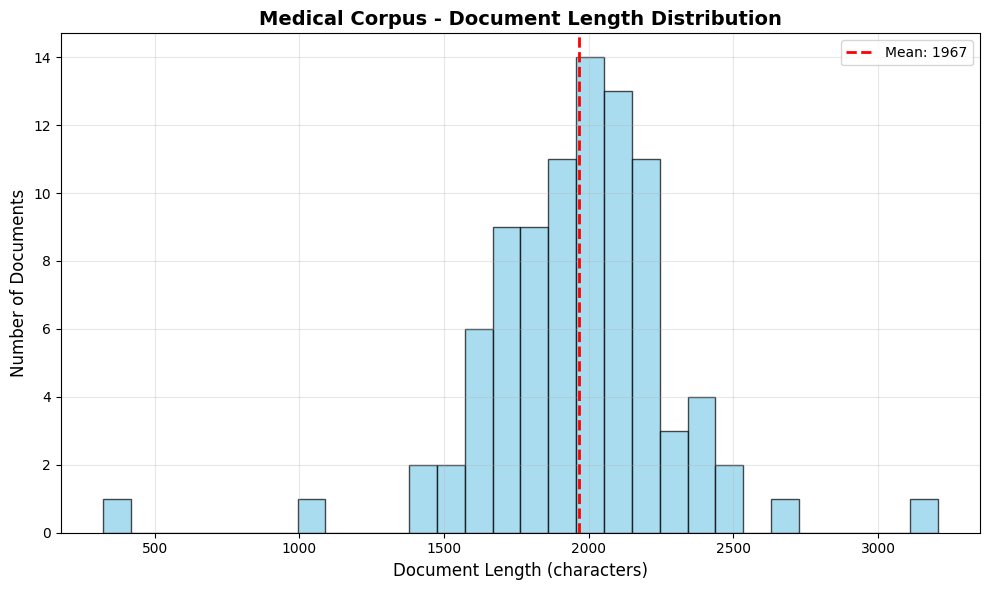

Total documents: 90
Average length: 1967 characters


In [ ]:
import matplotlib.pyplot as plt
content_lengths = [len(doc['content'])
                  for doc in data['documents']
                  if 'content' in doc and doc['content']]

# 히스토그램 그리기
plt.figure(figsize=(10, 6))
plt.hist(content_lengths, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Medical Corpus - Document Length Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Document Length (characters)', fontsize=12)
plt.ylabel('Number of Documents', fontsize=12)
plt.grid(True, alpha=0.3)

# 평균선 추가
mean_length = sum(content_lengths) / len(content_lengths)
plt.axvline(mean_length, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {mean_length:.0f}')
plt.legend()

plt.tight_layout()
plt.show()

print(f"Total documents: {len(content_lengths)}")
print(f"Average length: {mean_length:.0f} characters")

In [ ]:
for doc in data['documents']:
    if len(doc['content']) > 2800:
        print(doc)

{'index': 65, 'disease': '결핵', 'document_type': 'Drug types and mechanisms', 'level': 'Expert', 'content': '결핵의 약물 종류와 작용 기전\n\n결핵(Tuberculosis, TB)은 주로 Mycobacterium tuberculosis에 의해 발생하는 만성 감염성 질환으로, 효과적인 치료를 위해 다양한 항결핵제(antitubercular agents)가 사용됩니다. 결핵 치료의 핵심은 다제 병용요법(multi-drug therapy)이며, 이는 약제 내성(resistance) 발생을 억제하고 치료 성공률을 높이기 위함입니다. 본 문서에서는 결핵 치료에 사용되는 주요 약물의 종류와 각각의 작용 기전에 대해 심도 있게 다룹니다.\n\n1. 1차 항결핵제(First-line antitubercular drugs)\n\n1차 항결핵제는 결핵 치료의 표준 요법에서 가장 우선적으로 사용되는 약물로, 효과가 뛰어나고 내약성이 비교적 우수합니다. 대표적으로 이소니아지드, 리팜핀, 피라진아미드, 에탐부톨, 스트렙토마이신이 있습니다.\n\n1) 이소니아지드(Isoniazid, INH)\n- 작용 기전: 이소니아지드는 미코박테리아의 세포벽 합성에 필수적인 미콜산(mycolic acid) 합성을 억제합니다. 이는 카탈라아제-퍼옥시다아제 효소(KatG)에 의해 활성화된 후, InhA 효소를 저해하여 미콜산 생합성을 차단합니다.\n- 특징: 결핵균에 대해 살균적(bactericidal)으로 작용하며, 특히 증식기(active phase) 결핵균에 효과적입니다.\n\n2) 리팜핀(Rifampin, RIF)\n- 작용 기전: 리팜핀은 결핵균의 DNA 의존성 RNA 중합효소(DNA-dependent RNA polymerase)에 결합하여, mRNA 합성을 억제함으로써 단백질 합성을 차단합니다.\n- 특징: 광범위한 항균 스펙트럼을 가지며, 휴지기(persistent phase) 결핵균에도 효과가 있습니다.

생성된 Corpus는 이후 Continuous Pretraining 실습에 사용할 수 있습니다.

API 호출 메타데이터를 제거하고, 파일로 저장합니다.

In [ ]:
with open('medical_corpus.json', 'w', encoding='utf-8') as f:
    json.dump(data['documents'], f, ensure_ascii=False, indent=2)

print('medical corpus 생성 완료')

medical corpus 생성 완료
